# Model 1: Simple CNN

## 1. Cấu hình và thư viện

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, metrics, callbacks
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
import os
import hashlib
from collections import Counter

DATA_DIR = Path("/home/pc/AAA/project/deepnn/G8_AI66A_DNN/data/raw")
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

SETS = ["train", "val", "test"]
IMG_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 30
NUM_CLASSES = 4

2026-10-13 19:19:07.024026: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-13 19:19:07.032102: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-13 19:19:07.042436: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-13 19:19:07.042451: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-13 19:19:07.049232: I tensorflow/core/platform/cpu_feature_gua

In [2]:

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(VAL_DIR),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names
print(f"Các lớp: {class_names}")


Found 76515 files belonging to 4 classes.


2026-10-13 19:19:08.912763: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 19:19:08.936324: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 19:19:08.938582: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Found 21861 files belonging to 4 classes.
Found 10933 files belonging to 4 classes.
Các lớp: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


In [3]:
# # Tối ưu hóa tốc độ đọc dữ liệu
# AUTOTUNE = tf.data.AUTOTUNE
# train_ds = train_ds.prefetch(AUTOTUNE)
# val_ds = val_ds.prefetch(AUTOTUNE)
# test_ds = test_ds.prefetch(AUTOTUNE)

## 2. Preprocessing

### 2.1 Loại bỏ ảnh trùng lặp

In [4]:

# CLASS_NAMES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())


In [5]:
clean_samples = {se: [] for se in SETS}
seen_hash = {}
dup_count = Counter()

for se in ["test", "val", "train"]:
    se_dir = DATA_DIR / se
    
    for class_name in os.listdir(se_dir):
        class_dir = se_dir / class_name
        if not class_dir.is_dir():
            continue
            
        for img_path in class_dir.iterdir():
            if not img_path.is_file():
                continue
            
            # Tính mã MD5 của file ảnh
            with open(img_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()
            
            if file_hash in seen_hash:
                kept_in = seen_hash[file_hash]
                dup_count[(se, kept_in)] += 1
            else:
                seen_hash[file_hash] = se
                clean_samples[se].append((img_path, class_name))
            
print("Ảnh trùng bị loại:", sum(dup_count.values()))
for (drop_in, kept_in), n in dup_count.items():
    print(f"- {n} ảnh ở '{drop_in}' trùng với ảnh ở '{kept_in}'")
    
del seen_hash # Giải phóng bộ nhớ đệm hash sau khi dùng xong

clean_summary = pd.DataFrame({s: Counter(class_name for _, class_name in clean_samples[s]) for s in SETS}).fillna(0).astype(int)
clean_summary["total"] = clean_summary.sum(axis=1)
clean_summary.loc["TOTAL"] = clean_summary.sum()
print("\nSau khi làm sạch:")
clean_summary

Ảnh trùng bị loại: 7866
- 85 ảnh ở 'test' trùng với ảnh ở 'test'
- 345 ảnh ở 'val' trùng với ảnh ở 'test'
- 301 ảnh ở 'val' trùng với ảnh ở 'val'
- 2301 ảnh ở 'train' trùng với ảnh ở 'val'
- 1212 ảnh ở 'train' trùng với ảnh ở 'test'
- 3622 ảnh ở 'train' trùng với ảnh ở 'train'

Sau khi làm sạch:


,train,val,test,total
DRUSEN,5612,1722,879,8213
CNV,21034,7024,3678,31736
NORMAL,35002,10191,5135,50328
DME,7732,2278,1156,11166
TOTAL,69380,21215,10848,101443


### 2.2 Kiểm tra mất cân bằng lớp

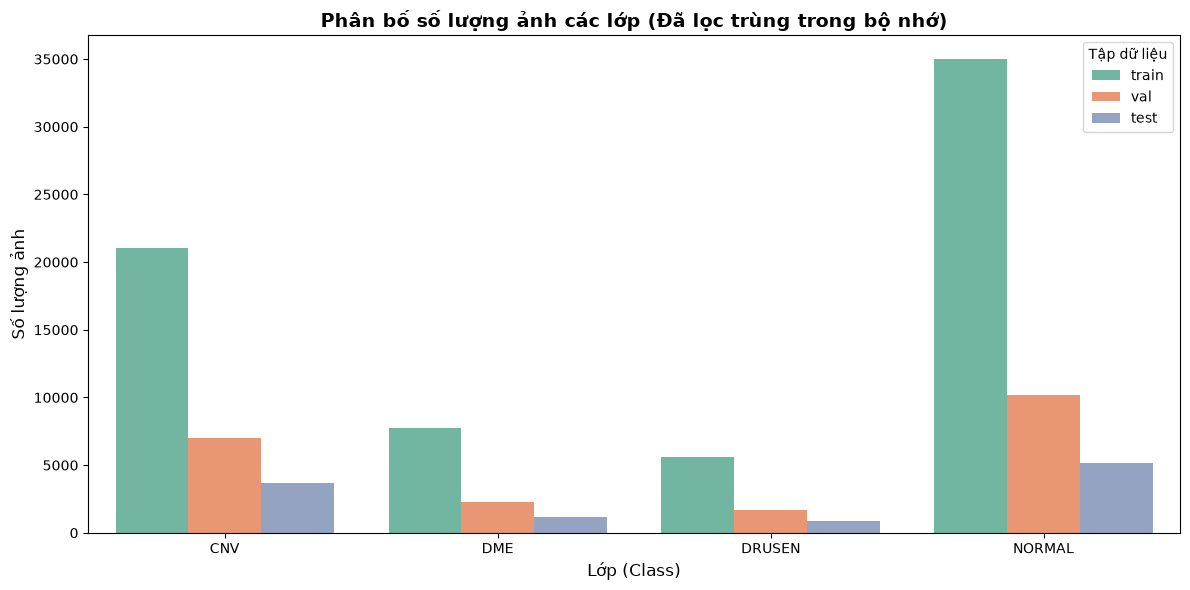

In [6]:
# Tạo DataFrame từ kết quả đếm để vẽ biểu đồ cho đẹp
data_summary = []
for split in SETS:
    # Đếm số lượng ảnh của từng lớp trong biến clean_samples
    split_counts = pd.Series([cls for _, cls in clean_samples[split]]).value_counts()
    for class_name in class_names:
        count = split_counts.get(class_name, 0)
        data_summary.append({"Split": split, "Class": class_name, "Count": count})
        
df_summary = pd.DataFrame(data_summary)

# Vẽ biểu đồ phân bố
plt.figure(figsize=(12, 6))
sns.barplot(data=df_summary, x="Class", y="Count", hue="Split", palette="Set2")
plt.title("Phân bố số lượng ảnh các lớp (Đã lọc trùng trong bộ nhớ)", fontsize=14, fontweight="bold")
plt.ylabel("Số lượng ảnh", fontsize=12)
plt.xlabel("Lớp (Class)", fontsize=12)
plt.legend(title="Tập dữ liệu")
plt.tight_layout()
plt.show()

=> Không bị mất cân bằng lớp nặng

### 2.3 Tính Mean và Std cho normalization

In [7]:
# Tính Mean và Std theo từng kênh RGB trên tập train
# Ảnh trong train_ds có dạng (batch, height, width, channels)
channel_sum = np.zeros(3, dtype=np.float64)
channel_squared_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0

for images, _ in train_ds:
    # Chuyển pixel từ [0, 255] về [0, 1]
    images = tf.cast(images, tf.float32) / 255.0

    # Cộng giá trị pixel theo từng kênh RGB
    channel_sum += tf.reduce_sum(
        images, axis=[0, 1, 2]
    ).numpy()

    # Cộng bình phương giá trị pixel theo từng kênh RGB
    channel_squared_sum += tf.reduce_sum(
        tf.square(images), axis=[0, 1, 2]
    ).numpy()

    # Đếm tổng số pixel đã xử lý trong mỗi kênh
    pixel_count += int(tf.shape(images)[0]) * IMG_SIZE * IMG_SIZE

# Mean của từng kênh
MEAN = channel_sum / pixel_count
# Phương sai = E[X²] - E[X]²
variance = channel_squared_sum / pixel_count - np.square(MEAN)
# Std = căn bậc hai của phương sai
STD = np.sqrt(np.maximum(variance, 0.0))

print("Mean (R, G, B):", MEAN.tolist())
print("Std  (R, G, B):", STD.tolist())

Mean (R, G, B): [0.18895403328482827, 0.18895403375845599, 0.18895403283612833]
Std  (R, G, B): [0.22028999145740644, 0.22028999177253966, 0.22028999099358762]


2026-10-13 19:19:30.473682: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 3. Xây dựng model

In [12]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),

    # Xoay tối đa khoảng +/- 15 độ
    layers.RandomRotation(15 / 360),

    # Zoom gần tương đương scale 0.9 - 1.1
    layers.RandomZoom(
        height_factor=(-0.1, 0.1),
        width_factor=(-0.1, 0.1)
    ),

    # Điều chỉnh độ sáng, tương phản và độ bão hòa màu
    # Thực hiện trước Rescaling để phù hợp thang pixel [0, 255]
    layers.RandomBrightness(factor=0.2),
    layers.RandomContrast(factor=0.2),
    layers.RandomSaturation(factor=0.2),

    # ==================================================
    # 2. RESCALING
    # Chuyển pixel từ [0, 255] sang [0, 1]
    # ==================================================
    layers.Rescaling(1.0 / 255),

    # ==================================================
    # 3. NORMALIZATION
    # MEAN và STD đã được tính trên train_ds ở thang [0, 1]
    # ==================================================
    layers.Normalization(
        axis=-1,
        mean=MEAN.astype("float32"),
        variance=np.square(STD.astype("float32"))
    ),
    
    # CNN    
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax')
])


In [9]:

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 128, 128, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 128, 128, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_saturation               │ (None, 128, 128, 3)    │             0 │
│ (RandomSaturation)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,483,140 (32.36 MB)

 Trainable params: 8,483,140 (32.36 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile model
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', metrics.F1Score(average='macro', name='f1_score')]
)

# Sử dụng Callbacks có sẵn thay vì tự viết vòng lặp early stopping thủ công
cb_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]

## 4. Huan luyen

In [14]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=cb_list
)

Epoch 1/30
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 84s 70ms/step - accuracy: 0.7662 - f1_score: 0.5280 - loss: 0.6679 - val_accuracy: 0.8430 - val_f1_score: 0.6698 - val_loss: 0.4745 - learning_rate: 0.0010
Epoch 2/30
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 84s 71ms/step - accuracy: 0.8596 - f1_score: 0.7178 - loss: 0.4137 - val_accuracy: 0.8657 - val_f1_score: 0.7618 - val_loss: 0.4150 - learning_rate: 0.0010
Epoch 3/30
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 82s 68ms/step - accuracy: 0.8875 - f1_score: 0.7936 - loss: 0.3346 - val_accuracy: 0.9039 - val_f1_score: 0.8221 - val_loss: 0.2878 - learning_rate: 0.0010
Epoch 4/30
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 85s 71ms/step - accuracy: 0.9048 - f1_score: 0.8305 - loss: 0.2893 - val_accuracy: 0.8993 - val_f1_score: 0.8237 - val_loss: 0.3284 - learning_rate: 0.0010
Epoch 5/30
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 82s 69ms/step - accuracy: 0.9124 - f1_score: 0.8466 - loss: 0.2658 - val_accuracy: 0.9096 - val_f1_score: 0.8366 - val_loss: 0.2785 - learning_rate: 0.0010
Epoch 6/30

## 5. Danh gia tren tap test

In [15]:
# Lấy ground truth và predictions
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

 23/171 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

2026-10-13 19:41:39.373686: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step



Classification Report:
              precision    recall  f1-score   support

         CNV       0.95      0.94      0.95      3746
         DME       0.94      0.75      0.84      1161
      DRUSEN       0.82      0.64      0.72       887
      NORMAL       0.91      1.00      0.95      5139

    accuracy                           0.92     10933
   macro avg       0.91      0.83      0.86     10933
weighted avg       0.92      0.92      0.92     10933



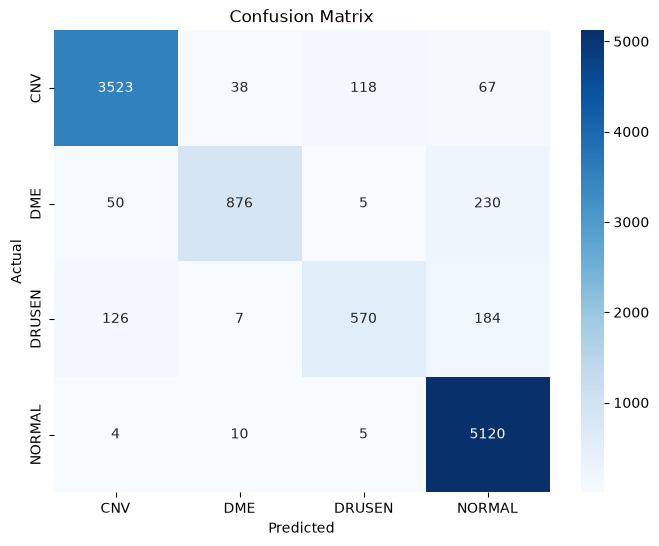

In [16]:
# In báo cáo
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [17]:
# Lưu model (giống cách lưu trong Training_model.ipynb)
model.save('model1_simple_cnn.keras')
print("Đã lưu model thành công!")

Đã lưu model thành công!
